In [ ]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches # for draw Bounding Box
from PIL import Image
import numpy as np

Image size: (810, 1080)


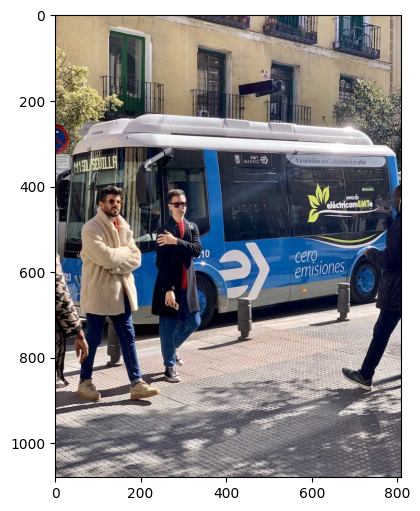

In [ ]:
from PIL import Image
import matplotlib.pyplot as plt
import requests
from io import BytesIO

url = "https://ultralytics.com/images/bus.jpg"

response = requests.get(url)
image = Image.open(BytesIO(response.content)).convert("RGB")

print("Image size:", image.size)

plt.figure(figsize=(10, 6))
plt.imshow(image)
plt.axis("on")
plt.show()

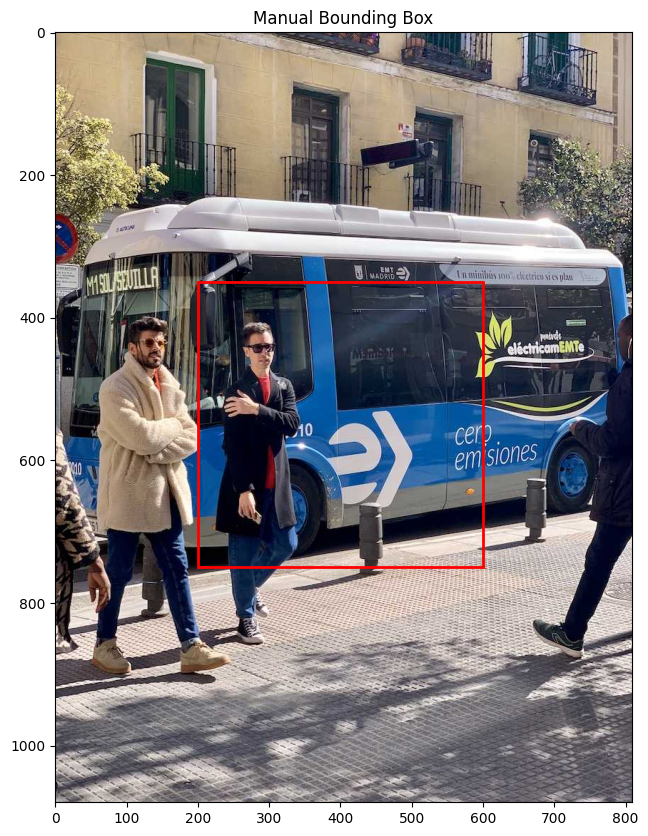

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches

# Bounding box: x1, y1, x2, y2
x1, y1, x2, y2 = 200, 350, 600, 750

fig, ax = plt.subplots(figsize=(8, 10))

ax.imshow(image)

# Create the bounding box
box = patches.Rectangle(
    (x1, y1),
    x2 - x1,    # width
    y2 - y1,    # height
    linewidth=2,
    edgecolor="red",
    facecolor="none"
)

ax.add_patch(box)
ax.set_title("Manual Bounding Box")
plt.show()

In [ ]:
class_to_id = {
    "car": 0,
    "pedestrian": 1
}

class_name = "car"
box = [200, 350, 600, 750]

class_id = class_to_id[class_name]

print("Class ID:", class_id)
print("Bounding Box:", box)
print("Box width:", box[2] - box[0])
print("Box height:", box[3] - box[1])

Class ID: 0
Bounding Box: [200, 350, 600, 750]
Box width: 400
Box height: 400


In [ ]:
objects = [
    {
        "class_id": 0,
        "box": [100, 200, 300, 400]
    },
    {
        "class_id": 0,
        "box": [350, 180, 600, 380]
    },
    {
        "class_id": 1,
        "box": [620, 250, 680, 420]
    }
]

for obj in objects:
    print("Class ID:", obj["class_id"])
    print("Bounding Box:", obj["box"])
    print("---")

Class ID: 0
Bounding Box: [100, 200, 300, 400]
---
Class ID: 0
Bounding Box: [350, 180, 600, 380]
---
Class ID: 1
Bounding Box: [620, 250, 680, 420]
---


In [ ]:
import torch

print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

PyTorch version: 2.11.0+cu130
GPU available: True


In [ ]:
!wget -q https://github.com/ultralytics/assets/releases/download/v0.0.0/kitti.zip -O kitti.zip

In [ ]:
import zipfile
from pathlib import Path

zip_path = Path("kitti.zip")

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall("kitti_data")

print("Extraction completed!")

Extraction completed!


In [ ]:
from pathlib import Path

data_dir = Path("kitti_data")

for path in list(data_dir.rglob("*"))[:30]:
    print(path)

kitti_data/kitti.yaml
kitti_data/images
kitti_data/labels
kitti_data/images/val
kitti_data/images/train
kitti_data/labels/val
kitti_data/labels/train
kitti_data/labels/val/006720.txt
kitti_data/labels/val/002806.txt
kitti_data/labels/val/006954.txt
kitti_data/labels/val/001865.txt
kitti_data/labels/val/001832.txt
kitti_data/labels/val/004473.txt
kitti_data/labels/val/006200.txt
kitti_data/labels/val/004591.txt
kitti_data/labels/val/002522.txt
kitti_data/labels/val/002227.txt
kitti_data/labels/val/005105.txt
kitti_data/labels/val/003928.txt
kitti_data/labels/val/002421.txt
kitti_data/labels/val/004317.txt
kitti_data/labels/val/003745.txt
kitti_data/labels/val/002514.txt
kitti_data/labels/val/005418.txt
kitti_data/labels/val/002772.txt
kitti_data/labels/val/002341.txt
kitti_data/labels/val/004302.txt
kitti_data/labels/val/002617.txt
kitti_data/labels/val/002013.txt
kitti_data/labels/val/004368.txt


In [ ]:
from pathlib import Path

label_dir = Path("kitti_data/labels/train")

label_files = sorted(label_dir.glob("*.txt"))

print("Number of label files:", len(label_files))
print("\nFirst label file:", label_files[0].name)
print("\nLabel content:")
print(label_files[0].read_text())

Number of label files: 5985

First label file: 000002.txt

Label content:
7 0.724726 0.660373 0.153494 0.428267
0 0.546481 0.551360 0.034364 0.088693


In [ ]:
from pathlib import Path

yaml_path = Path("kitti_data/kitti.yaml")

print(yaml_path.read_text())

# Ultralytics 🚀 AGPL-3.0 License - https://ultralytics.com/license

# Kitti dataset by Karlsruhe Institute of Technology and Toyota Technological Institute at Chicago
# Documentation: https://docs.ultralytics.com/datasets/detect/kitti/
# Example usage: yolo train data=kitti.yaml
# parent
# ├── ultralytics
# └── datasets
#     └── kitti ← downloads here (390.5 MB)

# Train/val/test sets as 1) dir: path/to/imgs, 2) file: path/to/imgs.txt, or 3) list: [path/to/imgs1, path/to/imgs2, ..]
path: kitti # dataset root dir
train: images/train # train images (relative to 'path') 5985 images
val: images/val # val images (relative to 'path') 1496 images

names:
  0: car
  1: van
  2: truck
  3: pedestrian
  4: Person_sitting
  5: cyclist
  6: tram
  7: misc

# Download script/URL (optional)
download: https://github.com/ultralytics/assets/releases/download/v0.0.0/kitti.zip



In [ ]:
from pathlib import Path

image_dir = Path("kitti_data/images/train")
label_dir = Path("kitti_data/labels/train")

image_path = sorted(image_dir.glob("*.png"))[0]
label_path = label_dir / f"{image_path.stem}.txt"

print("Image:", image_path.name)
print("Label:", label_path.name)
print("Label exists:", label_path.exists())

labels = label_path.read_text().strip().splitlines()

print("Number of objects:", len(labels))
print("\nAnnotations:")
print(label_path.read_text())

Image: 000002.png
Label: 000002.txt
Label exists: True
Number of objects: 2

Annotations:
7 0.724726 0.660373 0.153494 0.428267
0 0.546481 0.551360 0.034364 0.088693


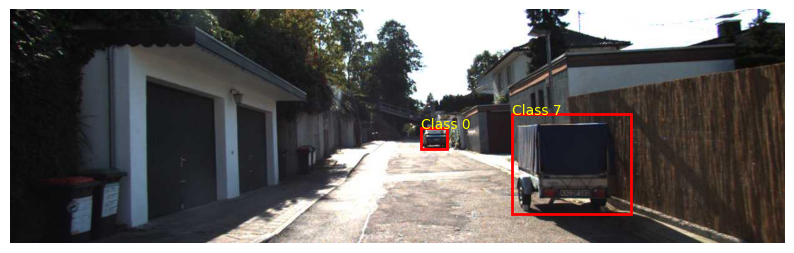

In [ ]:
from PIL import Image
import matplotlib.pyplot as plt
import matplotlib.patches as patches

# Load image
image = Image.open(image_path).convert("RGB")
img_width, img_height = image.size

fig, ax = plt.subplots(figsize=(10, 7))
ax.imshow(image)

for line in labels:
    class_id, x_center, y_center, width, height = map(
        float, line.split()
    )

    # Convert normalized values to pixels
    x_center *= img_width
    y_center *= img_height
    width *= img_width
    height *= img_height

    # Convert center coordinates to top-left coordinates
    x_min = x_center - width / 2
    y_min = y_center - height / 2

    box = patches.Rectangle(
        (x_min, y_min),
        width,
        height,
        linewidth=2,
        edgecolor="red",
        facecolor="none"
    )

    ax.add_patch(box)
    ax.text(x_min, y_min, f"Class {int(class_id)}", color="yellow")

ax.axis("off")
plt.show()

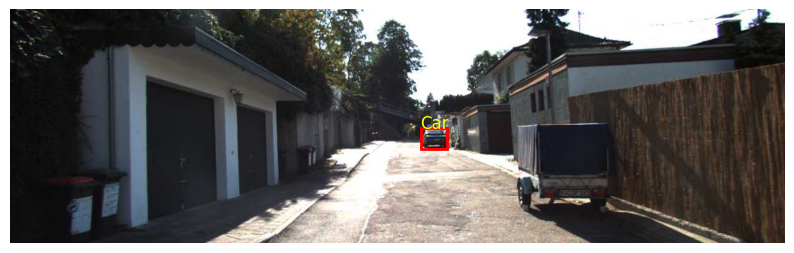

In [ ]:
class_names = {
    0: "Car",
    3: "Pedestrian"
}

fig, ax = plt.subplots(figsize=(10, 7))
ax.imshow(image)

for line in labels:
    class_id, x_center, y_center, width, height = map(
        float, line.split()
    )

    class_id = int(class_id)

    # Keep cars and pedestrians only
    if class_id not in class_names:
        continue

    x_center *= img_width
    y_center *= img_height
    width *= img_width
    height *= img_height

    x_min = x_center - width / 2
    y_min = y_center - height / 2

    box = patches.Rectangle(
        (x_min, y_min),
        width,
        height,
        linewidth=2,
        edgecolor="red",
        facecolor="none"
    )

    ax.add_patch(box)
    ax.text(
        x_min, y_min,
        class_names[class_id],
        color="yellow",
        fontsize=12
    )

ax.axis("off")
plt.show()

In [ ]:
from collections import Counter
from pathlib import Path

label_dir = Path("kitti_data/labels/train")

class_counts = Counter()

for label_file in label_dir.glob("*.txt"):
    for line in label_file.read_text().splitlines():
        if not line.strip():
            continue

        class_id = int(line.split()[0])
        class_counts[class_id] += 1

print("Cars:", class_counts[0])
print("Pedestrians:", class_counts[3])
print("All annotated objects:", sum(class_counts.values()))

Cars: 23026
Pedestrians: 3566
All annotated objects: 32442


In [ ]:
from collections import Counter
from pathlib import Path

label_dir = Path("kitti_data/labels/train")

image_counts = Counter()

for label_file in label_dir.glob("*.txt"):
    found_classes = set()

    for line in label_file.read_text().splitlines():
        if not line.strip():
            continue

        class_id = int(line.split()[0])

        if class_id in [0, 3]:
            found_classes.add(class_id)

    for class_id in found_classes:
        image_counts[class_id] += 1

print("Images containing cars:", image_counts[0])
print("Images containing pedestrians:", image_counts[3])

Images containing cars: 5362
Images containing pedestrians: 1402


In [ ]:
from pathlib import Path
from PIL import Image
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision.transforms.functional import to_tensor

image_dir = Path("kitti_data/images/train")
label_dir = Path("kitti_data/labels/train")

print("Images folder exists:", image_dir.exists())
print("Labels folder exists:", label_dir.exists())

Images folder exists: True
Labels folder exists: True


In [ ]:
from torchvision.transforms.functional import to_tensor

class KITTIDataset(Dataset):
    def __init__(self, image_dir, label_dir):
        self.image_dir = Path(image_dir)
        self.label_dir = Path(label_dir)

        self.image_paths = sorted(
            self.image_dir.glob("*.png")
        )

        self.class_names = {
            0: "Car",
            3: "Pedestrian"
        }

    def __len__(self):
      return len(self.image_paths)

    def __getitem__(self, idx):
      image_path= self.image_paths[idx]

      label_path= self.label_dir / f"{image_path.stem}.txt"

      image= Image.open(image_path).convert("RGB")

      boxes=[]
      labels=[]

      img_width , img_height = image.size

      for line in label_path.read_text().splitlines():
        if not line.strip():
          continue

        class_id ,x_center ,y_center ,width ,height = map(float, line.split())
        class_id= int(class_id)

        if class_id not in self.class_names:
          continue

        x_center *= img_width
        y_center *= img_height
        width *= img_width
        height *= img_height

        x_min = x_center - width / 2
        y_min = y_center - height / 2

        x_max = x_center + width / 2
        y_max = y_center + height / 2

        boxes.append([x_min , y_min , x_max , y_max])
        labels.append(class_id)

      image = to_tensor(image)

      target = {
          "boxes": torch.tensor(boxes , dtype=torch.float32).reshape(-1, 4), # Ensure boxes always have shape (num_boxes, 4), even when empty
          "labels": torch.tensor(labels , dtype=torch.int64)
      }

      return image , target

In [ ]:
train_dataset = KITTIDataset(
    image_dir="kitti_data/images/train",
    label_dir="kitti_data/labels/train"
)

print("Dataset size:", len(train_dataset))

image, target = train_dataset[0]

print("Image shape:", image.shape)
print("Boxes shape:", target["boxes"].shape)
print("Labels:", target["labels"])

Dataset size: 5985
Image shape: torch.Size([3, 375, 1242])
Boxes shape: torch.Size([1, 4])
Labels: tensor([0])


In [ ]:
for idx in [0, 1, 2, 10, 100]:
    image, target = train_dataset[idx]

    print(
        f"Image {idx}:",
        "Boxes =", len(target["boxes"]),
        "Labels =", target["labels"].tolist()
    )

Image 0: Boxes = 1 Labels = [0]
Image 1: Boxes = 1 Labels = [0]
Image 2: Boxes = 2 Labels = [0, 0]
Image 10: Boxes = 1 Labels = [0]
Image 100: Boxes = 8 Labels = [0, 0, 0, 0, 0, 0, 0, 0]


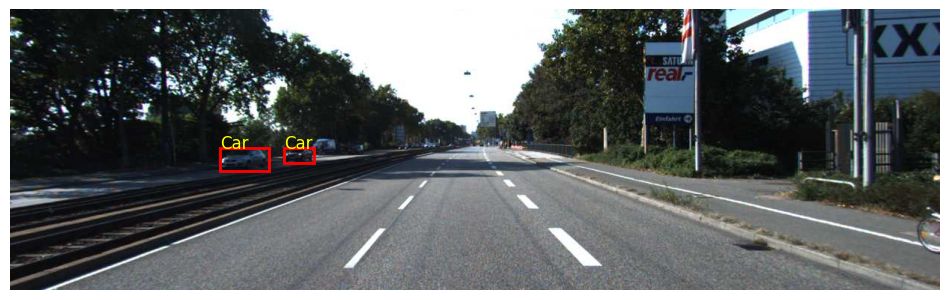

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches

idx = 2
image, target = train_dataset[idx]

# Convert image from [C, H, W] to [H, W, C]
image_np = image.permute(1, 2, 0).numpy()

fig, ax = plt.subplots(figsize=(12, 6))
ax.imshow(image_np)

for box, label in zip(target["boxes"], target["labels"]):
    x_min, y_min, x_max, y_max = box.tolist()

    rect = patches.Rectangle(
        (x_min, y_min),
        x_max - x_min,
        y_max - y_min,
        linewidth=2,
        edgecolor="red",
        facecolor="none"
    )

    ax.add_patch(rect)
    ax.text(
        x_min, y_min,
        train_dataset.class_names[label.item()],
        color="yellow",
        fontsize=12
    )

ax.axis("off")
plt.show()

In [ ]:
from torch.utils.data import DataLoader

train_loader = DataLoader(
    train_dataset,
    batch_size=4,
    shuffle=True,
    collate_fn=lambda batch: tuple(zip(*batch))
)

images, targets = next(iter(train_loader))

print("Number of images:", len(images))
print("First image shape:", images[0].shape)
print("First image boxes:", targets[0]["boxes"].shape)

Number of images: 4
First image shape: torch.Size([3, 375, 1242])
First image boxes: torch.Size([3, 4])


In [ ]:
val_dataset = KITTIDataset(
    "kitti_data/images/val",
    "kitti_data/labels/val"
)

val_loader = DataLoader(
    val_dataset,
    batch_size=4,
    shuffle=False,
    collate_fn=lambda batch: tuple(zip(*batch))
)

images, targets = next(iter(val_loader))

print("Validation dataset size:", len(val_dataset))
print("Number of images:", len(images))
print("First image shape:", images[0].shape)
print("First image boxes:", targets[0]["boxes"].shape)

Validation dataset size: 1496
Number of images: 4
First image shape: torch.Size([3, 370, 1224])
First image boxes: torch.Size([1, 4])


In [ ]:

class FasterRCNNDataset(KITTIDataset):
    def __getitem__(self, idx):
        image, target = super().__getitem__(idx)

        # Map KITTI IDs to Faster R-CNN IDs
        labels = target["labels"].clone()
        labels[labels == 0] = 1
        labels[labels == 3] = 2

        target["labels"] = labels

        return image, target

In [ ]:

faster_train_dataset = FasterRCNNDataset(
    "kitti_data/images/train",
    "kitti_data/labels/train"
)

faster_val_dataset = FasterRCNNDataset(
    "kitti_data/images/val",
    "kitti_data/labels/val"
)

print("Train size:", len(faster_train_dataset))
print("Validation size:", len(faster_val_dataset))

image, target = faster_train_dataset[0]
print("Image shape:", image.shape)
print("Labels:", target["labels"])
print("Boxes shape:", target["boxes"].shape)


Train size: 5985
Validation size: 1496
Image shape: torch.Size([3, 375, 1242])
Labels: tensor([1])
Boxes shape: torch.Size([1, 4])


In [ ]:

import torch
from torchvision.models.detection import (
    fasterrcnn_resnet50_fpn,
    FasterRCNN_ResNet50_FPN_Weights
)
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor

# Load pretrained Faster R-CNN
weights = FasterRCNN_ResNet50_FPN_Weights.DEFAULT
model = fasterrcnn_resnet50_fpn(weights=weights)

# Replace the classifier for 2 classes + background
in_features = model.roi_heads.box_predictor.cls_score.in_features
model.roi_heads.box_predictor = FastRCNNPredictor(
    in_features,
    num_classes=3
)

# Use GPU if available
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)

print("Device:", device)
print("Model loaded successfully!")

Downloading: "https://download.pytorch.org/models/fasterrcnn_resnet50_fpn_coco-258fb6c6.pth" to /root/.cache/torch/hub/checkpoints/fasterrcnn_resnet50_fpn_coco-258fb6c6.pth


100%|██████████| 160M/160M [00:01<00:00, 161MB/s]


Device: cuda
Model loaded successfully!


In [ ]:

from torch.utils.data import DataLoader

def collate_fn(batch):
    return tuple(zip(*batch))

faster_train_loader = DataLoader(
    faster_train_dataset,
    batch_size=4,
    shuffle=True,
    collate_fn=collate_fn
)

faster_val_loader = DataLoader(
    faster_val_dataset,
    batch_size=4,
    shuffle=False,
    collate_fn=collate_fn
)

print("Train batches:", len(faster_train_loader))
print("Validation batches:", len(faster_val_loader))

Train batches: 1497
Validation batches: 374


In [ ]:

images, targets = next(iter(faster_train_loader))

print("Number of images:", len(images))
print("First image shape:", images[0].shape)
print("First target boxes:", targets[0]["boxes"].shape)
print("First target labels:", targets[0]["labels"])

Number of images: 4
First image shape: torch.Size([3, 375, 1242])
First target boxes: torch.Size([4, 4])
First target labels: tensor([1, 1, 1, 1])


In [ ]:

import torch

# Set the model to training mode
model.train()

optimizer = torch.optim.SGD(
    [p for p in model.parameters() if p.requires_grad],
    lr=0.005,
    momentum=0.9,
    weight_decay=0.0005
)

# Test one training batch
images, targets = next(iter(faster_train_loader))

images = [img.to(device) for img in images]
targets = [
    {key: value.to(device) for key, value in target.items()}
    for target in targets
]

loss_dict = model(images, targets)
total_loss = sum(loss for loss in loss_dict.values())

print("Loss components:")
for name, loss in loss_dict.items():
    print(f"{name}: {loss.item():.4f}")

print("Total loss:", total_loss.item())

optimizer.zero_grad()
total_loss.backward()
optimizer.step()

print("One training step completed!")


Loss components:
loss_classifier: 1.0217
loss_box_reg: 0.6279
loss_objectness: 0.0366
loss_rpn_box_reg: 0.0325
Total loss: 1.7186970710754395
One training step completed!


In [ ]:

model.train()

total_loss = 0.0

for step, (images, targets) in enumerate(faster_train_loader, start=1):
    images = [img.to(device) for img in images]
    targets = [
        {key: value.to(device) for key, value in target.items()}
        for target in targets
    ]

    loss_dict = model(images, targets)
    loss = sum(loss for loss in loss_dict.values())

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    total_loss += loss.item()

    if step % 100 == 0:
        print(f"Step {step}/{len(faster_train_loader)} | Loss: {loss.item():.4f}")

average_loss = total_loss / len(faster_train_loader)

print(f"\nAverage Training Loss: {average_loss:.4f}")

Step 100/1497 | Loss: 0.3427
Step 200/1497 | Loss: 0.4899
Step 300/1497 | Loss: 0.3003
Step 400/1497 | Loss: 0.2334
Step 500/1497 | Loss: 0.2626
Step 600/1497 | Loss: 0.3894
Step 700/1497 | Loss: 0.3419
Step 800/1497 | Loss: 0.2200
Step 900/1497 | Loss: 0.3842
Step 1000/1497 | Loss: 0.4230
Step 1100/1497 | Loss: 0.4712
Step 1200/1497 | Loss: 0.2992
Step 1300/1497 | Loss: 0.2264
Step 1400/1497 | Loss: 0.2038

Average Training Loss: 0.3282


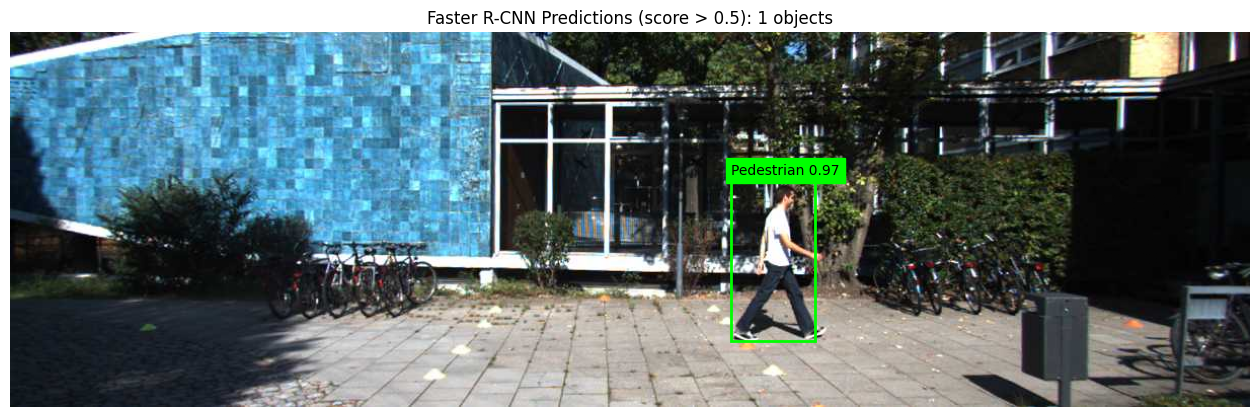

In [ ]:

import matplotlib.pyplot as plt
import matplotlib.patches as patches

model.eval()

image, target = faster_val_dataset[0]

with torch.no_grad():
    prediction = model([image.to(device)])[0]

# Keep predictions with confidence above 0.5
scores = prediction["scores"].cpu()
keep = scores > 0.5

pred_boxes = prediction["boxes"].cpu()[keep]
pred_labels = prediction["labels"].cpu()[keep]
pred_scores = scores[keep]

fig, ax = plt.subplots(figsize=(16, 6))
ax.imshow(image.permute(1, 2, 0))

class_names = {1: "Car", 2: "Pedestrian"}

for box, label, score in zip(pred_boxes, pred_labels, pred_scores):
    x1, y1, x2, y2 = box.tolist()

    rect = patches.Rectangle(
        (x1, y1), x2 - x1, y2 - y1,
        linewidth=2, edgecolor="lime", facecolor="none"
    )
    ax.add_patch(rect)
    ax.text(
        x1, y1, f"{class_names[label.item()]} {score:.2f}",
        color="black", backgroundcolor="lime"
    )

ax.set_title(f"Faster R-CNN Predictions (score > 0.5): {len(pred_boxes)} objects")
ax.axis("off")
plt.show()


In [ ]:
%pip install -q torchmetrics pycocotools

In [ ]:

from torchmetrics.detection.mean_ap import MeanAveragePrecision

metric = MeanAveragePrecision(
    box_format="xyxy",
    iou_type="bbox"
)

model.eval()

with torch.inference_mode():
    for step, (images, targets) in enumerate(faster_val_loader, start=1):
        images = [img.to(device) for img in images]

        predictions = model(images)

        # Prepare predictions and ground truth for evaluation
        preds = [
            {
                "boxes": pred["boxes"].cpu(),
                "scores": pred["scores"].cpu(),
                "labels": pred["labels"].cpu()
            }
            for pred in predictions
        ]

        ground_truths = [
            {
                "boxes": target["boxes"].cpu(),
                "labels": target["labels"].cpu()
            }
            for target in targets
        ]

        metric.update(preds, ground_truths)

        if step % 100 == 0:
            print(f"Evaluated {step}/{len(faster_val_loader)} batches")

results = metric.compute()

print(f"mAP@0.5:      {results['map_50'].item():.4f}")
print(f"mAP@0.5:0.95: {results['map'].item():.4f}")

Evaluated 100/374 batches
Evaluated 200/374 batches
Evaluated 300/374 batches
mAP@0.5:      0.7979
mAP@0.5:0.95: 0.4857


In [ ]:

from pathlib import Path
import shutil

src = Path("kitti_data")
dst = Path("kitti_yolo")

for split in ["train", "val"]:
    (dst / "images" / split).mkdir(parents=True, exist_ok=True)
    (dst / "labels" / split).mkdir(parents=True, exist_ok=True)

    # Reuse the images without copying them
    for image_path in (src / "images" / split).glob("*"):
        target_path = dst / "images" / split / image_path.name
        if not target_path.exists():
            shutil.copy2(image_path, target_path)

    # Keep Car and Pedestrian labels only
    for label_path in (src / "labels" / split).glob("*.txt"):
        new_lines = []

        for line in label_path.read_text().splitlines():
            parts = line.split()
            if not parts:
                continue

            class_id = int(parts[0])

            if class_id == 0:
                parts[0] = "0"  # Car
            elif class_id == 3:
                parts[0] = "1"  # Pedestrian
            else:
                continue

            new_lines.append(" ".join(parts))

        (dst / "labels" / split / label_path.name).write_text(
            "\n".join(new_lines)
        )

print("YOLO dataset prepared!")

YOLO dataset prepared!


In [ ]:

yaml_text = """
path: kitti_yolo
train: images/train
val: images/val

names:
  0: Car
  1: Pedestrian
"""

Path("kitti_yolo.yaml").write_text(yaml_text.strip() + "\n")
print(Path("kitti_yolo.yaml").read_text())

path: kitti_yolo
train: images/train
val: images/val

names:
  0: Car
  1: Pedestrian



In [ ]:
%pip install -q ultralytics

In [ ]:

from ultralytics import YOLO

yolo_model = YOLO("yolo11n.pt")

yolo_model.train(
    data="kitti_yolo.yaml",
    epochs=5,
    imgsz=640,
    batch=8,
    device=0 if torch.cuda.is_available() else "cpu",
    workers=2,
    name="kitti_car_pedestrian"
)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics 8.4.192 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=kitti_yolo.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=5, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hs

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7e6590df83b0>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0.04804